# What drives developer pay in 2026?

An analysis of the **Stack Overflow Developer Survey 2026** following the CRISP-DM process:
business understanding, data understanding, data preparation, modeling, evaluation and deployment
(communicating the results).

The data science steps are labelled throughout: **Gather → Assess → Clean → Analyze → Model → Visualize**.

## 1. Business understanding

Developers, hiring managers and people changing careers all ask the same thing: *what is a developer
actually paid, and what moves that number?* The 2026 survey adds questions on AI agents and work
setting, so it can answer questions earlier years could not.

| # | Business question | How it is answered |
|---|---|---|
| Q1 | What drives developer pay in 2026? | Permutation importance from a trained model, plus pay by the top features |
| Q2 | Do developers who use AI agents earn more, and how much of that survives once experience, role and country are taken into account? | Raw median gap compared with a model-adjusted gap |
| Q3 | Does remote work pay more in the United States? | Median pay by work setting, with a bootstrap 95% confidence interval |
| Q4 | How accurately can a model predict a developer's pay? | Held-out R², dollar error, and an above-median classifier (accuracy, precision, recall, F1) |
| Q5 | What would three specific developers be predicted to earn? | Scenario predictions with a 10th–90th percentile range |

Q3 does not need machine learning, so it uses descriptive and inferential statistics.

In [1]:
"""Imports, settings and output folders."""
import hashlib
import json
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
DATA_DIR = Path("data")
RAW_CSV = DATA_DIR / "raw" / "survey_results_public.csv"
RAW_SHA256 = "ad520b4d5d71f240141e63f0d6f81a3b1898cbdc69efe9ea985496533b15fc2c"
EXTRACT_CSV = DATA_DIR / "so_survey_2026_extract.csv.gz"
FIG_DIR = Path("docs") / "assets"
RESULTS_JSON = Path("results") / "summary.json"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_JSON.parent.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 60)
RESULTS = {}
print(
    "pandas",
    pd.__version__,
    "| numpy",
    np.__version__,
    "| matplotlib",
    matplotlib.__version__,
)

pandas 2.2.2 | numpy 2.0.1 | matplotlib 3.9.0


## 2. Data understanding

### Gather

The full survey file is 122 MB, above GitHub's 100 MB file limit, so this repository ships an
**extract**: every respondent, but only the columns this analysis uses. If the full file is present at
`data/raw/survey_results_public.csv`, the next cell verifies its SHA-256 against the published value
and rebuilds the extract from it. Otherwise it loads the shipped extract. Both paths produce the same table.

In [2]:
COLUMNS = [
    "ResponseId",
    "Employment",
    "CodeMain",
    "Country",
    "ConvertedCompYearly",
    "Role",
    "OrgSize",
    "Industry",
    "WorkSetting",
    "Education",
    "YearsCode",
    "WorkExp",
    "AISelect",
    "AIDaily",
]


def sha256_of(path):
    """Return the SHA-256 hex digest of a file, read in 1 MB chunks.

    Args:
        path (Path): file to hash.

    Returns:
        str: lowercase hexadecimal digest.
    """
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def gather_survey(raw_csv=RAW_CSV, extract_csv=EXTRACT_CSV):
    """Load the survey columns this analysis uses.

    When the full published file is present and its hash matches, the
    extract is rebuilt from it (gzip with a fixed timestamp, so the same
    input always gives the same bytes). Otherwise the extract shipped in
    the repository is loaded.

    Args:
        raw_csv (Path): location of the full survey CSV, if downloaded.
        extract_csv (Path): location of the column extract.

    Returns:
        pandas.DataFrame: one row per respondent, the columns in COLUMNS.
    """
    if raw_csv.exists():
        actual = sha256_of(raw_csv)
        if actual != RAW_SHA256:
            raise ValueError(f"{raw_csv} does not match the published SHA-256")
        frame = pd.read_csv(raw_csv, usecols=COLUMNS, low_memory=False)[
            COLUMNS
        ]
        frame.to_csv(
            extract_csv,
            index=False,
            compression={"method": "gzip", "mtime": 0},
        )
        print(f"Rebuilt {extract_csv} from {raw_csv} (hash verified)")
    else:
        print(f"Loading the shipped extract {extract_csv}")
    return pd.read_csv(extract_csv, low_memory=False)


survey = gather_survey()
print(f"{len(survey):,} respondents, {survey.shape[1]} columns")
survey.head()

Rebuilt data/so_survey_2026_extract.csv.gz from data/raw/survey_results_public.csv (hash verified)
30,903 respondents, 14 columns


,ResponseId,Employment,CodeMain,Country,ConvertedCompYearly,Role,OrgSize,Industry,WorkSetting,Education,YearsCode,WorkExp,AISelect,AIDaily
0,1,"Independent contractor, freelancer, or self-employed",I create code as a primary part of my job,Sri Lanka,NaN,"Developer, back-end",Less than 20 employees,Education,"Hybrid (some remote, leans heavy to in-person)","Master's degree (M.A., M.S., M.Eng., MBA, etc.)",NaN,NaN,General-purpose AI chat tools,NaN
1,2,Employed,I create code as a primary part of my job,Brazil,NaN,"Developer, full-stack","5,000 to 9,999 employees",Government,Remote,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",28.0,26.0,I don’t use AI tools,NaN
2,3,Retired,I create code as a primary part of my job,Ukraine,10000.0,"Developer, desktop or enterprise applications",NaN,NaN,NaN,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",20.0,37.0,NaN,NaN
3,4,Student,I create code as a primary part of my job,United States of America,NaN,Student,NaN,NaN,NaN,Primary/elementary school,7.0,1.0,AI agents or automated workflows;AI coding assistants or...,NaN
4,5,Employed,I create code as a primary part of my job,Germany,85296.0,"Developer, desktop or enterprise applications",100 to 499 employees,Software development,Remote,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",30.0,26.0,AI coding assistants or coding agents,NaN


### Assess

Before modelling, check what each column holds and where it is missing. Many respondents skipped the
later sections of the survey, so missing values are common and are themselves information.

In [3]:
def missing_profile(frame):
    """Summarise missing values per column.

    Args:
        frame (pandas.DataFrame): table to profile.

    Returns:
        pandas.DataFrame: missing count and share, largest first.
    """
    missing = frame.isna().sum()
    return pd.DataFrame(
        {"missing": missing, "share": (missing / len(frame)).round(3)}
    ).sort_values("missing", ascending=False)


missing_profile(survey)

,missing,share
AIDaily,20026,0.648
ConvertedCompYearly,17396,0.563
AISelect,13439,0.435
Industry,11994,0.388
OrgSize,9788,0.317
Country,9533,0.308
WorkSetting,6301,0.204
WorkExp,6296,0.204
YearsCode,5699,0.184
Role,5136,0.166


count       13507.0
mean       106535.0
std        445368.0
min             1.0
1%             32.0
5%           2000.0
50%         79610.0
95%        240000.0
99%        488594.0
max      31919350.0
Name: ConvertedCompYearly, dtype: float64
Salaries below $5,000: 1076
Salaries above $1,000,000: 26


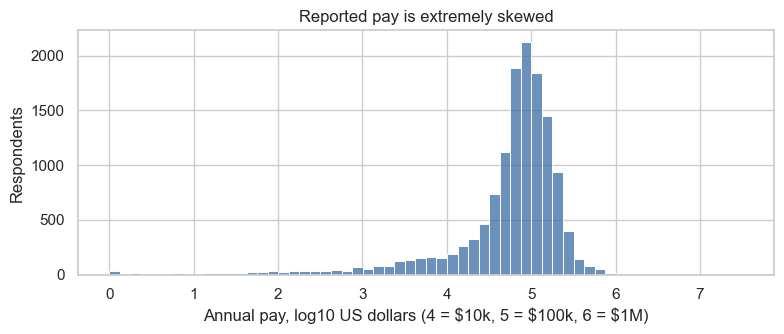

In [4]:
salary = survey["ConvertedCompYearly"]
print(salary.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(0))
print("Salaries below $5,000:", int((salary < 5_000).sum()))
print("Salaries above $1,000,000:", int((salary > 1_000_000).sum()))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(np.log10(salary.dropna()), bins=60, ax=ax, color="#3b6ea5")
ax.set(
    xlabel="Annual pay, log10 US dollars (4 = $10k, 5 = $100k, 6 = $1M)",
    ylabel="Respondents",
    title="Reported pay is extremely skewed",
)
plt.tight_layout()
plt.show()

**What the assessment shows**

- Pay is heavily right-skewed, with implausible values at both ends (values of $1 and above $30 million).
  Models are trained on the **log** of pay so a few huge salaries do not dominate.
- Pay is converted to US dollars by the survey team, but it still mixes countries with very different
  price levels, so country will matter a great deal.
- Missing values are widespread in later sections (industry, AI use, work setting). Dropping every row
  with a gap would discard most of the data and bias it toward people who finished the survey.

## 3. Data preparation

### Clean

1. **Keep the population the questions are about:** people who are employed or self-employed and who
   create code at least occasionally.
2. **Remove implausible pay:** keep $5,000 to $1,000,000 a year. Values outside that range are typos,
   monthly figures or currency mistakes far more often than real salaries.
3. **Group rare countries:** the 15 most common countries keep their names; the rest become "Other",
   so the model does not learn from a handful of respondents per country.
4. **Derive an AI-agent flag** from the multi-select `AISelect` question: "Uses AI agents" means the
   respondent ticked *AI agents or automated workflows*; people who skipped the question are kept as
   "No answer" rather than counted as non-users.

Age and gender are **deliberately left out of the model**: a pay model that uses protected attributes can
reproduce discrimination, and none of the business questions needs them.

In [5]:
EMPLOYED = ["Employed", "Independent contractor, freelancer, or self-employed"]
CODERS = [
    "I create code as a primary part of my job",
    "I create code occasionally",
]
PAY_RANGE = (5_000, 1_000_000)
TOP_COUNTRIES = 15


def clean_survey(frame):
    """Filter to the study population and derive analysis columns.

    Each step is recorded with the number of rows it removes, so the
    cleaning can be audited.

    Args:
        frame (pandas.DataFrame): gathered survey columns.

    Returns:
        tuple: (cleaned DataFrame, list of (step, rows_left) pairs).
    """
    steps = [("All respondents", len(frame))]
    kept = frame[frame["Employment"].isin(EMPLOYED)]
    steps.append(("Employed or self-employed", len(kept)))
    kept = kept[kept["CodeMain"].isin(CODERS)]
    steps.append(("Create code at least occasionally", len(kept)))
    kept = kept[kept["ConvertedCompYearly"].notna()]
    steps.append(("Reported pay", len(kept)))
    kept = kept[kept["ConvertedCompYearly"].between(*PAY_RANGE)].copy()
    steps.append(("Pay between $5,000 and $1,000,000", len(kept)))

    top = kept["Country"].value_counts().head(TOP_COUNTRIES).index
    kept["CountryGroup"] = kept["Country"].where(
        kept["Country"].isin(top), "Other"
    )
    uses_agents = kept["AISelect"].str.contains(
        "agents or automated", na=False
    )
    kept["AIAgents"] = np.where(
        kept["AISelect"].isna(),
        "No answer",
        np.where(uses_agents, "Uses AI agents", "No AI agents"),
    )
    kept["LogPay"] = np.log(kept["ConvertedCompYearly"])
    return kept, steps


developers, cleaning_steps = clean_survey(survey)
pd.DataFrame(cleaning_steps, columns=["Step", "Rows left"])

,Step,Rows left
0,All respondents,30903
1,Employed or self-employed,24866
2,Create code at least occasionally,22839
3,Reported pay,11712
4,"Pay between $5,000 and $1,000,000",10954


### Handling categorical and missing values

| Column type | Approach | Why it fits this data |
|---|---|---|
| Categorical (country, role, industry, …) | Missing → its own `Missing` category, then one-hot encoding; categories with fewer than 20 respondents are pooled | Skipping a question is informative (later survey sections were optional), and one-hot encoding suits unordered categories. Pooling rare categories prevents learning from tiny groups. |
| Numeric (years coding, years working) | Median imputation **plus** an indicator column for "was missing" | Keeps every row while letting the model learn whether a missing answer behaves differently. |
| Descriptive questions (Q2, Q3) | Rows missing the variable being compared are excluded from that comparison only, and counts are shown | A median of "unknown" is not a comparison anyone asked for, and showing counts makes the sample size visible. |

All imputation and encoding happens **inside** the model pipeline, so it is learned from training rows only
and applied unchanged to test rows (no leakage).

In [6]:
CATEGORICAL = [
    "CountryGroup",
    "Role",
    "OrgSize",
    "Industry",
    "WorkSetting",
    "Education",
    "AIDaily",
    "AIAgents",
    "Employment",
]
NUMERIC = ["YearsCode", "WorkExp"]
FEATURES = CATEGORICAL + NUMERIC


def make_preprocessor():
    """Build the shared preprocessing step for every model.

    Returns:
        sklearn.compose.ColumnTransformer: categorical columns imputed with
        'Missing' and one-hot encoded (rare levels pooled); numeric columns
        median-imputed with a missing-value indicator.
    """
    categorical = make_pipeline(
        SimpleImputer(strategy="constant", fill_value="Missing"),
        OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=20,
            sparse_output=False,
        ),
    )
    numeric = SimpleImputer(strategy="median", add_indicator=True)
    return ColumnTransformer(
        [
            ("categorical", categorical, CATEGORICAL),
            ("numeric", numeric, NUMERIC),
        ]
    )


X = developers[FEATURES]
y = developers["LogPay"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,} | held-out test rows: {len(X_test):,}")

Training rows: 8,763 | held-out test rows: 2,191


## 4. Modeling

Three candidates, compared with **5-fold cross-validation on the training rows only**. The test rows are
kept back and used once, at the end.

- **Dummy** — predicts the average log pay for everyone. Any useful model must beat it.
- **Ridge regression** — a regularised linear model; fast and interpretable.
- **Histogram gradient boosting** — an ensemble of trees that can capture interactions such as
  "experience pays more in some countries than others".

**A note for Apple-silicon Macs.** NumPy 2 on macOS uses Apple's Accelerate library for matrix
multiplication, and Accelerate can raise false "divide by zero / overflow / invalid value encountered in
matmul" warnings even when the answer is correct (NumPy's 2.3.0 release notes call them a known,
harmless Accelerate problem). Only the ridge model multiplies matrices here, so `compare_models` hides
exactly those matmul warnings and nothing else, and then **checks every score is a finite number**. A real
overflow would produce an infinite or missing score and stop the notebook, so the warning is hidden but the
problem it could signal is still caught.

In [7]:
MATMUL_WARNING = (
    r"(divide by zero|overflow|invalid value) encountered in matmul"
)


def compare_models(candidates, features, target, folds=5):
    """Cross-validate each candidate pipeline on the training data.

    Args:
        candidates (dict): name -> unfitted estimator (the final step).
        features (pandas.DataFrame): training features.
        target (pandas.Series): training target (log pay).
        folds (int): number of cross-validation folds.

    Returns:
        pandas.DataFrame: mean and standard deviation of R², and MAE,
        on the log scale.

    Raises:
        ValueError: if any score is infinite or missing.
    """
    splitter = KFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name, estimator in candidates.items():
        with warnings.catch_warnings():
            # False alarms from Apple's Accelerate library (see the note
            # above); only matmul warnings are hidden, nothing else.
            warnings.filterwarnings(
                "ignore", category=RuntimeWarning, message=MATMUL_WARNING
            )
            scores = cross_validate(
                make_pipeline(make_preprocessor(), estimator),
                features,
                target,
                cv=splitter,
                scoring=["r2", "neg_mean_absolute_error"],
            )
        rows.append(
            {
                "model": name,
                "cv_r2_mean": scores["test_r2"].mean(),
                "cv_r2_std": scores["test_r2"].std(),
                "cv_mae_log": -scores["test_neg_mean_absolute_error"].mean(),
            }
        )
    table = pd.DataFrame(rows).set_index("model")
    if not np.isfinite(table.to_numpy()).all():
        raise ValueError(f"a cross-validation score is not finite:\n{table}")
    return table.round(3)


CANDIDATES = {
    "Dummy (predict the mean)": DummyRegressor(),
    "Ridge regression": Ridge(alpha=1.0),
    "Gradient boosting": HistGradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
}
cv_table = compare_models(CANDIDATES, X_train, y_train)
RESULTS["cv"] = cv_table.reset_index().to_dict(orient="records")
cv_table

,cv_r2_mean,cv_r2_std,cv_mae_log
model,,,
Dummy (predict the mean),-0.001,0.001,0.608
Ridge regression,0.482,0.015,0.412
Gradient boosting,0.526,0.013,0.389


In [8]:
pay_model = make_pipeline(
    make_preprocessor(),
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
)
pay_model.fit(X_train, y_train)
print("Final model: gradient boosting, fitted on all training rows")

Final model: gradient boosting, fitted on all training rows


## 5. Evaluation — Q4: How accurately can a model predict pay?

The model is scored **once** on the held-out test rows. R² is on the log scale it was trained on; dollar
errors convert predictions back to dollars so they can be read directly.

In [9]:
def regression_report(model, features, log_target):
    """Score a log-pay model on held-out rows in both log and dollar terms.

    Args:
        model: fitted pipeline predicting log pay.
        features (pandas.DataFrame): held-out features.
        log_target (pandas.Series): held-out log pay.

    Returns:
        dict: R² (log scale), mean and median absolute error in dollars, and
        median absolute percentage error.
    """
    predicted = np.exp(model.predict(features))
    actual = np.exp(log_target)
    absolute = np.abs(predicted - actual)
    return {
        "r2_log": r2_score(log_target, np.log(predicted)),
        "mae_usd": mean_absolute_error(actual, predicted),
        "median_abs_error_usd": float(np.median(absolute)),
        "median_abs_pct_error": float(np.median(absolute / actual)),
    }


baseline = make_pipeline(make_preprocessor(), DummyRegressor()).fit(
    X_train, y_train
)
test_model = regression_report(pay_model, X_test, y_test)
test_baseline = regression_report(baseline, X_test, y_test)
RESULTS["test_regression"] = test_model
RESULTS["test_baseline"] = test_baseline
pd.DataFrame(
    {"Gradient boosting": test_model, "Dummy baseline": test_baseline}
).round(3)

,Gradient boosting,Dummy baseline
r2_log,0.507,-0.005
mae_usd,35156.647,53212.963
median_abs_error_usd,21111.623,33384.711
median_abs_pct_error,0.255,0.403


The project brief asks for accuracy and recall. Those are **classification** metrics and do not apply to a
continuous target like pay. To answer that part of the brief honestly, the same features are used to train a
classifier for a yes/no question: *does this developer earn more than the median of the training data?*

In [10]:
def classification_report_above_median(
    features_train, pay_train, features_test, pay_test
):
    """Train and score an 'above the training median' pay classifier.

    Args:
        features_train (pandas.DataFrame): training features.
        pay_train (pandas.Series): training log pay.
        features_test (pandas.DataFrame): held-out features.
        pay_test (pandas.Series): held-out log pay.

    Returns:
        tuple: (dict of metrics for the model and a majority-class baseline,
        the median threshold in dollars).
    """
    threshold = pay_train.median()
    label_train = (pay_train > threshold).astype(int)
    label_test = (pay_test > threshold).astype(int)
    scores = {}
    for name, estimator in {
        "Gradient boosting classifier": HistGradientBoostingClassifier(
            random_state=RANDOM_STATE
        ),
        "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    }.items():
        model = make_pipeline(make_preprocessor(), estimator).fit(
            features_train, label_train
        )
        predicted = model.predict(features_test)
        scores[name] = {
            "accuracy": accuracy_score(label_test, predicted),
            "precision": precision_score(
                label_test, predicted, zero_division=0
            ),
            "recall": recall_score(label_test, predicted, zero_division=0),
            "f1": f1_score(label_test, predicted, zero_division=0),
        }
    return scores, float(np.exp(threshold))


classifier_scores, median_threshold = classification_report_above_median(
    X_train, y_train, X_test, y_test
)
RESULTS["classifier"] = classifier_scores
RESULTS["median_threshold_usd"] = median_threshold
print(f"Threshold: ${median_threshold:,.0f} a year (training median)")
pd.DataFrame(classifier_scores).round(3)

Threshold: $85,296 a year (training median)


,Gradient boosting classifier,Majority-class baseline
accuracy,0.781,0.471
precision,0.811,0.000
recall,0.765,0.000
f1,0.787,0.000


Saved docs/assets/q4_accuracy.png


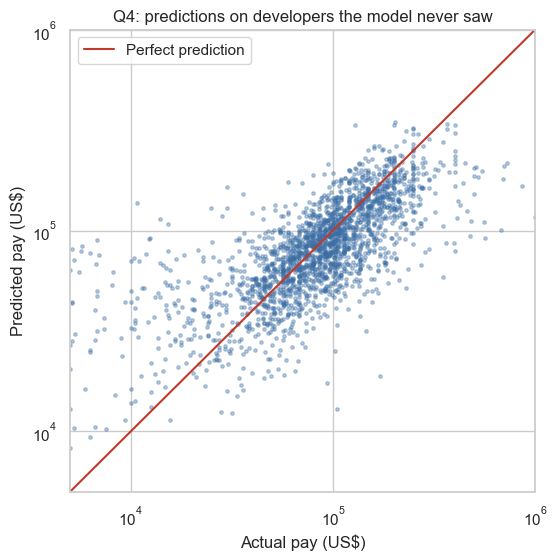

Answer to Q4: on 2,191 held-out developers the typical (median) miss is $21,112, 26% of salary, against $33,385 for guessing the average (R² 0.51 on log pay). As an above/below $85,296 classifier it is 78% accurate (precision 81%, recall 76%).


In [11]:
def state_answer(question, text):
    """Print a question's answer as one line built from computed values.

    Every number in the answer comes from variables computed above, so the
    written answer cannot drift from the results.

    Args:
        question (str): question label, e.g. 'Q4'.
        text (str): the answer.
    """
    print(f"Answer to {question}: {text}")


DOLLARS_K = matplotlib.ticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_figure(fig, name):
    """Save a figure into docs/assets for the blog post and show it.

    Args:
        fig (matplotlib.figure.Figure): figure to save.
        name (str): file name, e.g. 'q4_accuracy.png'.
    """
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.as_posix()}")
    plt.show()


fig, ax = plt.subplots(figsize=(6, 6))
predicted_usd = np.exp(pay_model.predict(X_test))
actual_usd = np.exp(y_test)
ax.scatter(actual_usd, predicted_usd, s=6, alpha=0.35, color="#3b6ea5")
limits = [5_000, 1_000_000]
ax.plot(
    limits, limits, color="#c0392b", linewidth=1.5, label="Perfect prediction"
)
ax.set(
    xscale="log",
    yscale="log",
    xlim=limits,
    ylim=limits,
    xlabel="Actual pay (US$)",
    ylabel="Predicted pay (US$)",
    title="Q4: predictions on developers the model never saw",
)
ax.legend()
save_figure(fig, "q4_accuracy.png")
gb_clf = classifier_scores["Gradient boosting classifier"]
state_answer(
    "Q4",
    f"on {len(X_test):,} held-out developers the typical (median) miss is "
    f"${test_model['median_abs_error_usd']:,.0f}, "
    f"{test_model['median_abs_pct_error']:.0%} of salary, against "
    f"${test_baseline['median_abs_error_usd']:,.0f} for guessing the "
    f"average (R² {test_model['r2_log']:.2f} on log pay). As an "
    f"above/below ${median_threshold:,.0f} classifier it is "
    f"{gb_clf['accuracy']:.0%} accurate (precision {gb_clf['precision']:.0%}, "
    f"recall {gb_clf['recall']:.0%}).",
)

## 6. Analyze and visualize — Q1: What drives developer pay?

**Permutation importance** shuffles one column at a time in the held-out data and measures how much the
model's R² drops. A large drop means the model relied on that column. It is computed on held-out rows, so
it is not inflated by memorised training data, and it treats every column fairly regardless of how many
categories it has.

Saved docs/assets/q1_importance.png


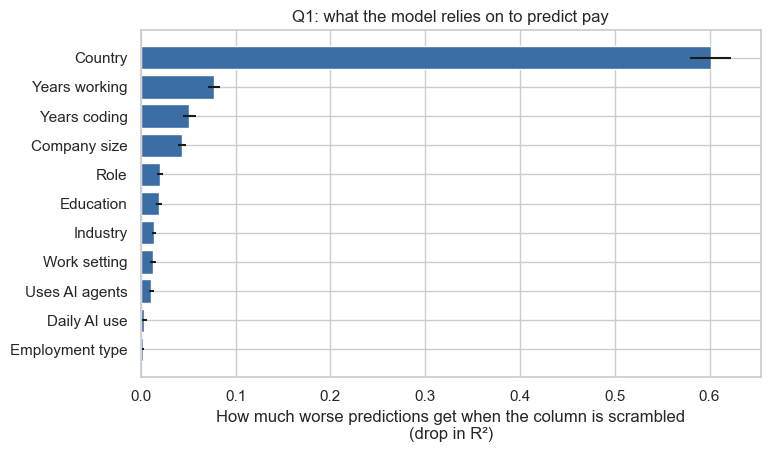

,feature,r2_drop,std
0,CountryGroup,0.6014,0.0215
1,WorkExp,0.0769,0.0065
2,YearsCode,0.0511,0.0067
3,OrgSize,0.0432,0.0044
4,Role,0.0200,0.0031
5,Education,0.0192,0.0027
6,Industry,0.0136,0.0022
7,WorkSetting,0.0126,0.0031
8,AIAgents,0.0111,0.0028
9,AIDaily,0.0039,0.0023


In [12]:
importance = permutation_importance(
    pay_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=RANDOM_STATE,
)
importance_table = (
    pd.DataFrame(
        {
            "feature": FEATURES,
            "r2_drop": importance.importances_mean,
            "std": importance.importances_std,
        }
    )
    .sort_values("r2_drop", ascending=False)
    .reset_index(drop=True)
)
RESULTS["importance"] = importance_table.round(4).to_dict(orient="records")

LABELS = {
    "CountryGroup": "Country",
    "WorkExp": "Years working",
    "YearsCode": "Years coding",
    "Role": "Role",
    "OrgSize": "Company size",
    "Industry": "Industry",
    "WorkSetting": "Work setting",
    "Education": "Education",
    "AIDaily": "Daily AI use",
    "AIAgents": "Uses AI agents",
    "Employment": "Employment type",
}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(
    importance_table["feature"].map(LABELS),
    importance_table["r2_drop"],
    xerr=importance_table["std"],
    color="#3b6ea5",
)
ax.invert_yaxis()
ax.set(
    xlabel="How much worse predictions get when the column is scrambled\n"
    "(drop in R²)",
    ylabel="",
    title="Q1: what the model relies on to predict pay",
)
save_figure(fig, "q1_importance.png")
importance_table.round(4)

Saved docs/assets/q1_country.png


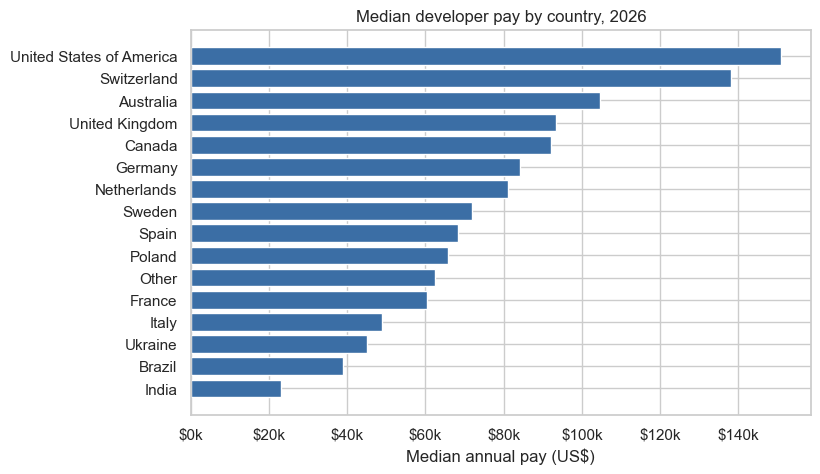

,median_pay,respondents
CountryGroup,,
United States of America,151000.0,2717
Switzerland,138040.0,219
Australia,104550.0,292
United Kingdom of Great Britain and Northern Ireland,93364.0,801
Canada,92188.0,512
Germany,84159.0,1133
Netherlands,81031.5,338
Sweden,71965.0,226
Spain,68237.0,303


In [13]:
def median_pay_by(frame, column, min_count=30):
    """Median pay and respondent count per category.

    Only groups with at least min_count respondents are reported.

    Args:
        frame (pandas.DataFrame): cleaned developers.
        column (str): category column to group by.
        min_count (int): smallest group reported.

    Returns:
        pandas.DataFrame: median pay and count, highest median first.
    """
    grouped = frame.groupby(column)["ConvertedCompYearly"].agg(
        median_pay="median", respondents="count"
    )
    return grouped[grouped["respondents"] >= min_count].sort_values(
        "median_pay", ascending=False
    )


country_pay = median_pay_by(developers, "CountryGroup")
RESULTS["country_median"] = {
    k: float(v) for k, v in country_pay["median_pay"].items()
}

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    country_pay.index.str.replace(
        " of Great Britain and Northern Ireland", ""
    ),
    country_pay["median_pay"],
    color="#3b6ea5",
)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(DOLLARS_K)
ax.set(
    xlabel="Median annual pay (US$)",
    ylabel="",
    title="Median developer pay by country, 2026",
)
save_figure(fig, "q1_country.png")
country_pay

Saved docs/assets/q1_experience.png


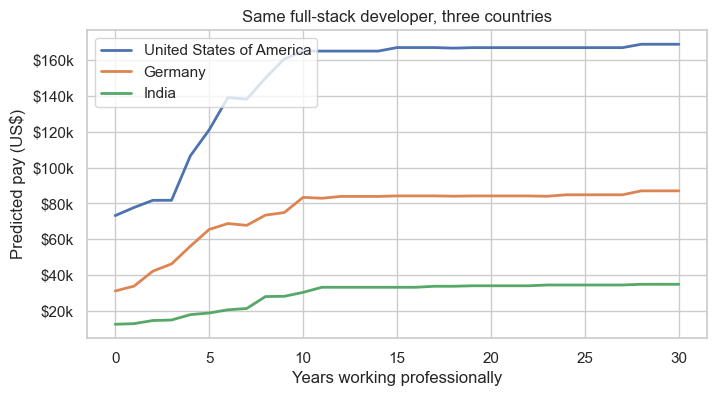

Answer to Q1: country drives pay most: shuffling it cuts R² by 0.60, about 8 times the next factor, years working. Median pay runs from $22,981 (India) to $151,000 (United States of America). Experience pays mostly in the first decade: $73,232 at 0 years, $165,083 at 10, $167,010 at 20 (US).


In [14]:
def experience_curve(model, template, years=range(0, 31)):
    """Predicted pay across years of experience for one fixed profile.

    Args:
        model: fitted log-pay pipeline.
        template (dict): feature values for the profile (WorkExp is varied).
        years (iterable): years of professional experience to evaluate.

    Returns:
        pandas.Series: predicted pay in dollars, indexed by years.
    """
    rows = pd.DataFrame(
        [{**template, "WorkExp": y, "YearsCode": y + 4} for y in years]
    )
    return pd.Series(np.exp(model.predict(rows[FEATURES])), index=list(years))


TYPICAL = {
    "Role": "Developer, full-stack",
    "OrgSize": "100 to 499 employees",
    "Industry": "Software development",
    "WorkSetting": "Remote",
    "Education": "Bachelor's degree (B.A., B.S., B.Eng., etc.)",
    "AIDaily": "1-2 hours/day",
    "AIAgents": "No AI agents",
    "Employment": "Employed",
}
curves = {
    country: experience_curve(pay_model, {**TYPICAL, "CountryGroup": country})
    for country in ["United States of America", "Germany", "India"]
}
RESULTS["experience_curve_us"] = {
    "years_0": float(curves["United States of America"][0]),
    "years_10": float(curves["United States of America"][10]),
    "years_20": float(curves["United States of America"][20]),
}
fig, ax = plt.subplots(figsize=(8, 4))
for country, curve in curves.items():
    ax.plot(curve.index, curve.values, linewidth=2, label=country)
ax.yaxis.set_major_formatter(DOLLARS_K)
ax.set(
    xlabel="Years working professionally",
    ylabel="Predicted pay (US$)",
    title="Same full-stack developer, three countries",
)
ax.legend()
save_figure(fig, "q1_experience.png")
top, second = importance_table["feature"].iloc[:2]
drops = importance_table.set_index("feature")["r2_drop"]
us_curve = curves["United States of America"]
state_answer(
    "Q1",
    f"{LABELS[top].lower()} drives pay most: shuffling it cuts R² by "
    f"{drops[top]:.2f}, about {drops[top] / drops[second]:.0f} times the "
    f"next factor, {LABELS[second].lower()}. Median pay runs from "
    f"${country_pay['median_pay'].min():,.0f} "
    f"({country_pay['median_pay'].idxmin()}) to "
    f"${country_pay['median_pay'].max():,.0f} "
    f"({country_pay['median_pay'].idxmax()}). Experience pays mostly in "
    f"the first decade: ${us_curve[0]:,.0f} at 0 years, "
    f"${us_curve[10]:,.0f} at 10, ${us_curve[20]:,.0f} at 20 (US).",
)

## 7. Q2: Do developers who use AI agents earn more?

Comparing medians alone mixes the effect of AI agents with everything that comes with them: agent users may
be more senior, in better-paid roles or in richer countries. So the question is answered twice:

1. **Raw gap** — median pay of agent users against non-users.
2. **Adjusted gap** — for every held-out developer, ask the model what it predicts with `AIAgents` set to
   "Uses AI agents" and to "No AI agents", keeping everything else about them the same.
   The average ratio is the gap that remains after experience, role, country and the rest are held fixed.

This is an association learned by the model, **not** proof that adopting AI agents raises pay.

Saved docs/assets/q2_ai_agents.png


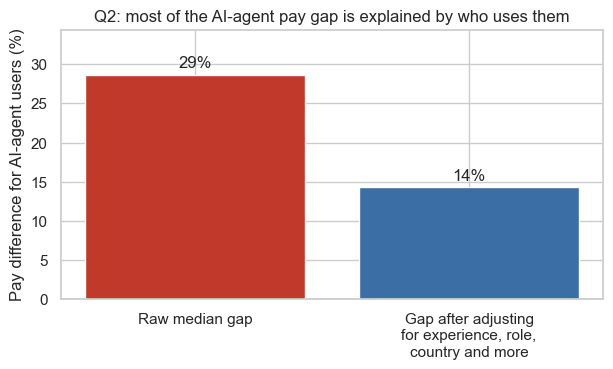

Answer to Q2: yes, but less than it looks. AI-agent users' median pay is $103,726 against $80,632 (29% higher); with experience, role, country and the rest held fixed the gap is 14%. This is an association, not a cause.


median_users        103726.500
median_non_users     80632.000
count_users           2872.000
count_non_users       6545.000
raw_gap                  0.286
adjusted_gap             0.143
dtype: float64

In [15]:
def raw_and_adjusted_gap(frame, model, features):
    """Compare the raw and model-adjusted pay gaps for AI-agent users.

    Args:
        frame (pandas.DataFrame): cleaned developers (for the raw medians).
        model: fitted log-pay pipeline.
        features (pandas.DataFrame): held-out rows for the adjusted gap.

    Returns:
        dict: medians, the raw gap and the adjusted gap (as fractions).
    """
    answered = frame[frame["AIAgents"] != "No answer"]
    medians = answered.groupby("AIAgents")["ConvertedCompYearly"].median()
    counts = answered["AIAgents"].value_counts()
    with_agents = features.assign(AIAgents="Uses AI agents")
    without_agents = features.assign(AIAgents="No AI agents")
    ratio = np.exp(model.predict(with_agents) - model.predict(without_agents))
    return {
        "median_users": float(medians["Uses AI agents"]),
        "median_non_users": float(medians["No AI agents"]),
        "count_users": int(counts["Uses AI agents"]),
        "count_non_users": int(counts["No AI agents"]),
        "raw_gap": float(
            medians["Uses AI agents"] / medians["No AI agents"] - 1
        ),
        "adjusted_gap": float(ratio.mean() - 1),
    }


ai_gap = raw_and_adjusted_gap(developers, pay_model, X_test)
RESULTS["ai_agents"] = ai_gap
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(
    [
        "Raw median gap",
        "Gap after adjusting\nfor experience, role,\ncountry and more",
    ],
    [ai_gap["raw_gap"] * 100, ai_gap["adjusted_gap"] * 100],
    color=["#c0392b", "#3b6ea5"],
)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.set_ylim(0, max(ai_gap["raw_gap"], ai_gap["adjusted_gap"]) * 100 * 1.2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    ylabel="Pay difference for AI-agent users (%)",
    title="Q2: most of the AI-agent pay gap is explained by who uses them",
)
save_figure(fig, "q2_ai_agents.png")
state_answer(
    "Q2",
    f"yes, but less than it looks. AI-agent users' median pay is "
    f"${ai_gap['median_users']:,.0f} against "
    f"${ai_gap['median_non_users']:,.0f} ({ai_gap['raw_gap']:.0%} higher); "
    f"with experience, role, country and the rest held fixed the gap is "
    f"{ai_gap['adjusted_gap']:.0%}. This is an association, not a cause.",
)
pd.Series(ai_gap).round(3)

## 8. Q3: Does remote work pay more in the United States?

Restricted to the United States, so the comparison is not distorted by countries with different pay levels
and different remote-work rates. The 95% confidence interval for the difference in medians comes from
2,000 bootstrap resamples. As in Q2, the model is then asked how much of the gap remains when the same
US developers are switched between "Remote" and "In-person" with everything else held fixed.

Saved docs/assets/q3_remote.png


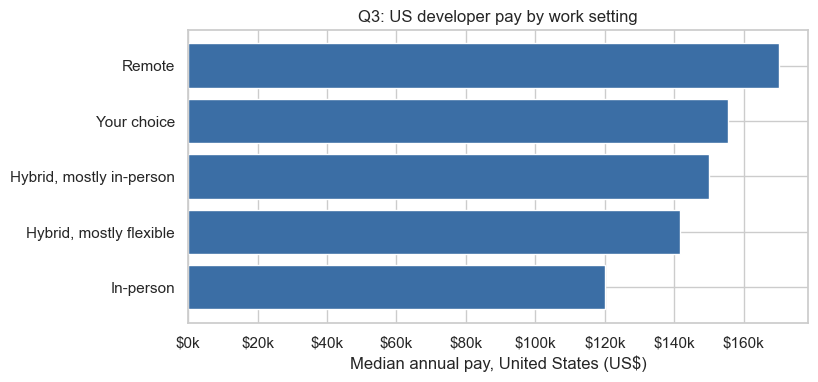

Answer to Q3: in raw terms, yes: remote $170,000 against in-person $120,000, a $50,000 gap (95% interval $38,500 to $59,500). Holding every other feature fixed, remote is worth only about 4%: most of the gap is who works remotely.


,median_pay,respondents
WorkSetting,,
Remote,170000.0,1322
"Your choice (very flexible, you can come in when you want or just as needed)",155500.0,196
"Hybrid (some remote, leans heavy to in-person)",150000.0,458
"Hybrid (some in-person, leans heavy to flexibility)",141500.0,334
In-person,120000.0,406


In [16]:
def bootstrap_median_gap(first, second, resamples=2000, seed=RANDOM_STATE):
    """Bootstrap a 95% confidence interval for median(first) - median(second).

    Args:
        first (array-like): pay values for the first group.
        second (array-like): pay values for the second group.
        resamples (int): number of bootstrap resamples.
        seed (int): random seed for reproducibility.

    Returns:
        dict: the observed gap and the 2.5th and 97.5th percentiles.
    """
    rng = np.random.default_rng(seed)
    first, second = np.asarray(first), np.asarray(second)
    gaps = [
        np.median(rng.choice(first, first.size))
        - np.median(rng.choice(second, second.size))
        for _ in range(resamples)
    ]
    return {
        "gap": float(np.median(first) - np.median(second)),
        "ci_low": float(np.percentile(gaps, 2.5)),
        "ci_high": float(np.percentile(gaps, 97.5)),
    }


us = developers[developers["Country"] == "United States of America"]
setting_pay = median_pay_by(us, "WorkSetting")
remote = us.loc[us["WorkSetting"] == "Remote", "ConvertedCompYearly"]
in_person = us.loc[us["WorkSetting"] == "In-person", "ConvertedCompYearly"]
remote_gap = bootstrap_median_gap(remote, in_person)
us_test = X_test[X_test["CountryGroup"] == "United States of America"]
remote_ratio = np.exp(
    pay_model.predict(us_test.assign(WorkSetting="Remote"))
    - pay_model.predict(us_test.assign(WorkSetting="In-person"))
)
RESULTS["remote_us"] = {
    **remote_gap,
    "median_remote": float(remote.median()),
    "adjusted_gap": float(remote_ratio.mean() - 1),
    "raw_gap_pct": float(remote.median() / in_person.median() - 1),
    "median_in_person": float(in_person.median()),
    "count_remote": int(remote.size),
    "count_in_person": int(in_person.size),
}

SHORT = {
    "Remote": "Remote",
    "In-person": "In-person",
    "Hybrid (some remote, leans heavy to in-person)": (
        "Hybrid, mostly in-person"
    ),
    "Hybrid (some in-person, leans heavy to flexibility)": (
        "Hybrid, mostly flexible"
    ),
    "Your choice (very flexible, you can come in when you want "
    "or just as needed)": "Your choice",
}
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(
    setting_pay.index.map(SHORT), setting_pay["median_pay"], color="#3b6ea5"
)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(DOLLARS_K)
ax.set(
    xlabel="Median annual pay, United States (US$)",
    ylabel="",
    title="Q3: US developer pay by work setting",
)
save_figure(fig, "q3_remote.png")
rem = RESULTS["remote_us"]
state_answer(
    "Q3",
    f"in raw terms, yes: remote ${rem['median_remote']:,.0f} against "
    f"in-person ${rem['median_in_person']:,.0f}, a ${rem['gap']:,.0f} gap "
    f"(95% interval ${rem['ci_low']:,.0f} to ${rem['ci_high']:,.0f}). "
    f"Holding every other feature fixed, remote is worth only about "
    f"{rem['adjusted_gap']:.0%}: most of the gap is who works remotely.",
)
setting_pay

## 9. Q5: What would three specific developers earn?

Three scenarios are predicted with the trained model. A point prediction hides how uncertain pay is, so two
extra models trained with **quantile loss** give a 10th–90th percentile range: 8 in 10 developers with that
profile would be expected to fall inside it. Each prediction is also compared with the median actual pay of
similar respondents (same country and role, experience within three years), as a sanity check.

Saved docs/assets/q5_scenarios.png


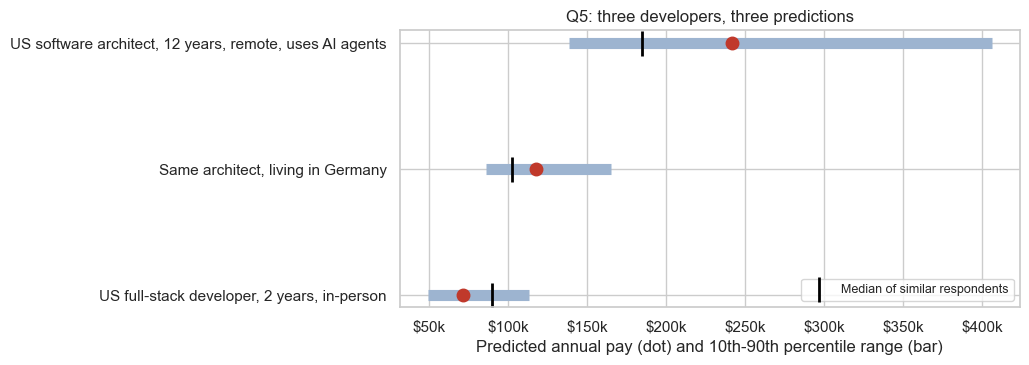

Answer to Q5: US software architect, 12 years, remote, uses AI agents: $241,930 ($138,578 to $405,861; similar respondents $185,000) | Same architect, living in Germany: $118,104 ($86,210 to $165,105; similar respondents $102,355) | US full-stack developer, 2 years, in-person: $71,869 ($49,522 to $113,516; similar respondents $90,000)


,predicted_pay,low_10th,high_90th,similar_median,similar_count
scenario,,,,,
"US software architect, 12 years, remote, uses AI agents",241930.0,138578.0,405861.0,185000.0,39
"Same architect, living in Germany",118104.0,86210.0,165105.0,102355.0,29
"US full-stack developer, 2 years, in-person",71869.0,49522.0,113516.0,90000.0,152


In [17]:
SCENARIOS = {
    "US software architect, 12 years, remote, uses AI agents": {
        "CountryGroup": "United States of America",
        "Role": "Architect, software or solutions",
        "OrgSize": "1,000 to 4,999 employees",
        "Industry": "Software development",
        "WorkSetting": "Remote",
        "Education": "Bachelor's degree (B.A., B.S., B.Eng., etc.)",
        "AIDaily": "2-4 hours/day",
        "AIAgents": "Uses AI agents",
        "Employment": "Employed",
        "YearsCode": 16,
        "WorkExp": 12,
    },
    "Same architect, living in Germany": {"CountryGroup": "Germany"},
    "US full-stack developer, 2 years, in-person": {
        "CountryGroup": "United States of America",
        "Role": "Developer, full-stack",
        "OrgSize": "20 to 99 employees",
        "Industry": "Software development",
        "WorkSetting": "In-person",
        "Education": "Bachelor's degree (B.A., B.S., B.Eng., etc.)",
        "AIDaily": "1-2 hours/day",
        "AIAgents": "No AI agents",
        "Employment": "Employed",
        "YearsCode": 6,
        "WorkExp": 2,
    },
}


def build_scenarios(scenarios):
    """Expand scenario dictionaries into a feature table.

    A scenario may list only the fields that differ from the previous one.

    Args:
        scenarios (dict): name -> dict of feature values.

    Returns:
        pandas.DataFrame: one row per scenario, columns in FEATURES order.
    """
    rows, previous = [], {}
    for name, values in scenarios.items():
        previous = {**previous, **values}
        rows.append({"scenario": name, **previous})
    return pd.DataFrame(rows).set_index("scenario")[FEATURES]


def similar_respondents(frame, profile, years=3):
    """Median actual pay of respondents who resemble a scenario.

    Similar means the same country and role, with professional experience
    within +/- years of the scenario. This is a sanity check on the model,
    not a prediction.

    Args:
        frame (pandas.DataFrame): cleaned developers.
        profile (pandas.Series): one scenario row.
        years (int): experience window either side.

    Returns:
        tuple: (median pay or NaN, number of similar respondents).
    """
    match = frame[
        (frame["CountryGroup"] == profile["CountryGroup"])
        & (frame["Role"] == profile["Role"])
        & frame["WorkExp"].between(
            profile["WorkExp"] - years, profile["WorkExp"] + years
        )
    ]
    pay = match["ConvertedCompYearly"]
    return (float(pay.median()) if len(pay) else float("nan")), int(len(pay))


def quantile_model(quantile):
    """Fit a gradient-boosting model for one quantile of log pay.

    Args:
        quantile (float): the quantile to predict, between 0 and 1.

    Returns:
        sklearn.pipeline.Pipeline: fitted pipeline.
    """
    estimator = HistGradientBoostingRegressor(
        loss="quantile", quantile=quantile, random_state=RANDOM_STATE
    )
    return make_pipeline(make_preprocessor(), estimator).fit(X_train, y_train)


scenario_rows = build_scenarios(SCENARIOS)
low_model, high_model = quantile_model(0.1), quantile_model(0.9)
scenario_table = pd.DataFrame(
    {
        "predicted_pay": np.exp(pay_model.predict(scenario_rows)),
        "low_10th": np.exp(low_model.predict(scenario_rows)),
        "high_90th": np.exp(high_model.predict(scenario_rows)),
    },
    index=scenario_rows.index,
)
similar = [
    similar_respondents(developers, row) for _, row in scenario_rows.iterrows()
]
scenario_table["similar_median"] = [median for median, _ in similar]
scenario_table["similar_count"] = [count for _, count in similar]
RESULTS["scenarios"] = {
    name: {k: float(v) for k, v in row.items()}
    for name, row in scenario_table.iterrows()
}

fig, ax = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(scenario_table))
ax.hlines(
    positions,
    scenario_table["low_10th"],
    scenario_table["high_90th"],
    color="#9db4d0",
    linewidth=8,
)
ax.plot(
    scenario_table["predicted_pay"],
    positions,
    "o",
    color="#c0392b",
    markersize=9,
)
ax.plot(
    scenario_table["similar_median"],
    positions,
    "|",
    color="black",
    markersize=18,
    markeredgewidth=2,
    label="Median of similar respondents",
)
ax.set_yticks(positions, scenario_table.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(DOLLARS_K)
ax.legend(loc="lower right", fontsize=9)
ax.set(
    xlabel="Predicted annual pay (dot) and 10th-90th percentile range (bar)",
    title="Q5: three developers, three predictions",
)
save_figure(fig, "q5_scenarios.png")
state_answer(
    "Q5",
    " | ".join(
        f"{name}: ${row.predicted_pay:,.0f} "
        f"(${row.low_10th:,.0f} to ${row.high_90th:,.0f}; similar "
        f"respondents ${row.similar_median:,.0f})"
        for name, row in scenario_table.iterrows()
    ),
)
scenario_table.round(0)

## 10. Deployment: communicating the results

The findings are written up for a non-technical audience in the blog post linked from the README. The
figures in `docs/assets/` are the ones produced above, and every number quoted in the README and the blog
comes from `results/summary.json`, written by the next cell.

Saved docs/assets/hero.png


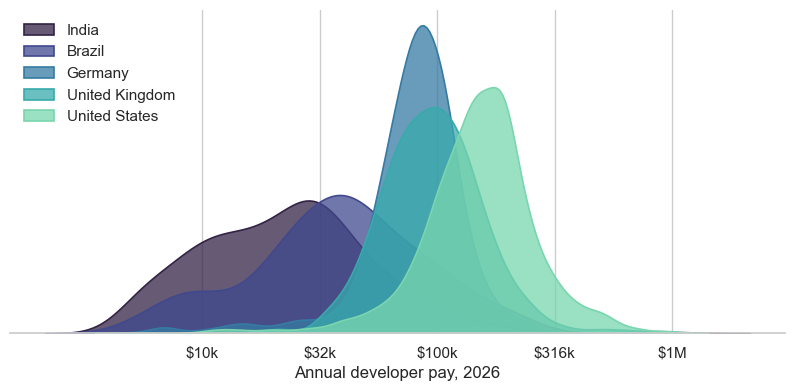

Wrote results/summary.json


In [18]:
def save_results(results, path=RESULTS_JSON):
    """Write the analysis results to JSON with stable formatting.

    Args:
        results (dict): figures produced by this notebook.
        path (Path): output file.
    """
    summary = {
        "rows": {
            "respondents": int(len(survey)),
            "developers": int(len(developers)),
            "train": int(len(X_train)),
            "test": int(len(X_test)),
        },
        "cleaning": [{"step": s, "rows": int(n)} for s, n in cleaning_steps],
        **results,
    }
    path.write_text(
        json.dumps(summary, indent=2, sort_keys=True, default=float) + "\n"
    )
    print(f"Wrote {path.as_posix()}")


def hero_image():
    """Draw the blog's title image: pay distributions for five countries.

    Returns:
        matplotlib.figure.Figure: the figure (saved as hero.png by
        the caller).
    """
    countries = [
        "India",
        "Brazil",
        "Germany",
        "United Kingdom of Great Britain and Northern Ireland",
        "United States of America",
    ]
    fig, ax = plt.subplots(figsize=(10, 4.2))
    palette = sns.color_palette("mako", len(countries))
    for country, colour in zip(countries, palette, strict=True):
        pay = np.log10(
            developers.loc[
                developers["CountryGroup"] == country, "ConvertedCompYearly"
            ]
        )
        sns.kdeplot(
            pay,
            ax=ax,
            fill=True,
            color=colour,
            alpha=0.75,
            linewidth=1.2,
            label=country.replace(
                " of Great Britain and Northern Ireland", ""
            ).replace(" of America", ""),
        )
    ax.set_xticks(
        [4, 4.5, 5, 5.5, 6], ["$10k", "$32k", "$100k", "$316k", "$1M"]
    )
    ax.set(xlabel="Annual developer pay, 2026", ylabel="", yticks=[])
    ax.legend(frameon=False, loc="upper left")
    sns.despine(left=True)
    return fig


save_figure(hero_image(), "hero.png")
save_results(RESULTS)

## 11. Conclusions

Each question's answer is printed under its own analysis above ("Answer to Q1" to "Answer to Q5"), built from
the computed values. The same answers are summarised in the README and told for a general audience in the blog
post. Limitations to keep in mind:

- **Self-reported, self-selected data.** Respondents chose to take a Stack Overflow survey; they are not a
  random sample of all developers.
- **Pay converted to US dollars** without adjusting for living costs, which is part of why country dominates.
- **Associations, not causes.** The AI-agent and remote-work gaps describe who earns what, not what would
  happen if someone changed how they work.
- **One survey year.** The 2026 survey changed several questions, so its figures are not directly comparable
  with earlier years.